In [1]:
import pandas as pd

# Load the Excel file
file_path = './data/final_0903.xlsx'
data_df = pd.read_excel(file_path)  # 첫 번째 행을 건너뛰고 읽기

/source/ms/env/highlight/lib/python3.8/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [2]:
# 첫 번째 제공된 표에 기반한 매핑을 설정합니다.
type_mapping = {
    'A7B3': 'DP', 'AZ8F': 'Threshold', 'AX2N': 'Random',
    'BH5Z': 'DP', 'BZ7J': 'Threshold', 'BP1Y': 'Random',
    # 'CT4C': 'DP', 'CM6D': 'Threshold', 'CL9K': 'Random',
    'DE2R': 'DP', 'DZ6Q': 'Threshold', 'DE4K': 'Random',
    'ER8G': 'DP', 'EZ2L': 'Threshold', 'EJ1N': 'Random',
    'FA1N': 'DP', 'FZ3K': 'Threshold', 'FB7R': 'Random',

}


In [3]:

# 성별, 이름, 소요시간 열 이름 정의
gender_column = 'Q6'
name_column = 'Q1'
time_column = 'Duration (in seconds)'  # 소요 시간 열

# Extract the relevant parts of the column names and map them to the appropriate type (DP, Threshold, Random)
def clean_column_name(name):
    for key in type_mapping.keys():
        if key in name:
            return f"{key}_{name.split('_')[-1]}"  # 예를 들어 A7B3_1, A7B3_2 등을 만듭니다.
    return name

# Apply the cleaning function to all column names
data_df.columns = data_df.columns.map(clean_column_name)

# JSON 변환 함수 정의
def convert_to_json(row):
    question_data = {}
    
    for question_id, question_type in type_mapping.items():
        if question_id[0] not in question_data:
            question_data[question_id[0]] = {
                "Q1": {},
                "Q2": {},
                "Q3": {}
            }
        
        question_data[question_id[0]]["Q1"][question_type] = int(row.get(f'{question_id}_1', 0))
        question_data[question_id[0]]["Q2"][question_type] = int(row.get(f'{question_id}_2', 0))
        question_data[question_id[0]]["Q3"][question_type] = int(row.get(f'{question_id}_3', 0))
    
    return {
        "name": row.get(name_column, "Unknown"),
        "time": int(row.get(time_column, 0)) // 60,  # 소요시간을 분으로 변환
        "gender": row.get(gender_column, "Unknown"),
        "question": question_data
    }

# 모든 사람의 데이터를 JSON으로 변환
json_data_list = []
for _, row in data_df.iloc[1:].iterrows():  # 첫 번째 행은 열 이름이므로 두 번째 행부터 시작
    json_data_list.append(convert_to_json(row))




In [4]:
import json
output_file_path = 'output_json_data_list.json'

with open(output_file_path, 'w', encoding='utf-8') as f:
    json.dump(json_data_list, f, ensure_ascii=False, indent=4)

In [5]:
import json
import matplotlib.pyplot as plt
import numpy as np

# JSON 파일 불러오기

with open(output_file_path, 'r', encoding='utf-8') as f:
    json_data_list = json.load(f)


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


[5.273333333333333, 5.593333333333334, 5.433333333333334] [4.1466666666666665, 5.026666666666666, 4.593333333333334] [4.06, 4.153333333333333, 3.993333333333333]


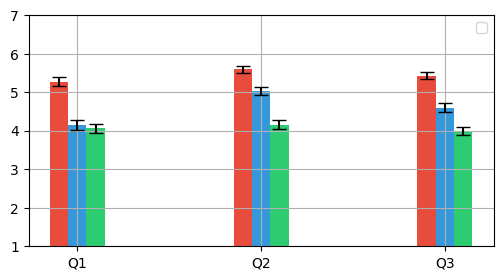

In [6]:

# 질문별 데이터를 추출
def extract_question_data(json_data_list, question_number):
    dp_values = []
    threshold_values = []
    random_values = []
    keys = ['A', 'B', 'D', 'E', 'F']
    for data in json_data_list:
        for key in keys:
            question_data = data['question'][key][f"Q{question_number}"]
            dp_values.append(question_data['DP'])
            threshold_values.append(question_data['Threshold'])
            random_values.append(question_data['Random'])
    
    return dp_values, threshold_values, random_values

# 데이터를 추출하고 세 질문의 데이터를 한 그래프에 표현하는 코드
# 데이터를 추출하고 세 질문의 데이터를 한 그래프에 표현하는 코드 (표준 오차 사용)
def plot_combined_question_data():
    dp_means, threshold_means, random_means = [], [], []
    dp_sems, threshold_sems, random_sems = [], [], []  # 표준 오차 계산을 위한 리스트

    for i in range(1, 4):
        dp_values, threshold_values, random_values = extract_question_data(json_data_list, i)
        
        dp_means.append(np.mean(dp_values))
        threshold_means.append(np.mean(threshold_values))
        random_means.append(np.mean(random_values))
        
        dp_sems.append(np.std(dp_values) / np.sqrt(len(dp_values)))
        threshold_sems.append(np.std(threshold_values) / np.sqrt(len(threshold_values)))
        random_sems.append(np.std(random_values) / np.sqrt(len(random_values)))

    # 그래프 생성
    labels = ['Q1', 'Q2', 'Q3']
    x = np.arange(len(labels))  # the label locations
    width = 0.1  # the width of the bars

    fig, ax = plt.subplots(figsize=(6, 3))
    
    # 각각의 막대 그래프
    ax.bar(x - width, dp_means, width, yerr=dp_sems, capsize=5, color='#e74c3c')
    ax.bar(x, threshold_means, width, yerr=threshold_sems, capsize=5, color='#3498db')
    ax.bar(x + width, random_means, width, yerr=random_sems, capsize=5, color='#2ecc71')
    print(dp_means, threshold_means, random_means)
    # 그래프 설정
    # ax.set_xlabel('Questions')
    # ax.set_ylabel('Scores')
    ax.set_ylim(1, 7)
    ax.grid(True)
    # ax.set_title('Average Scores with Standard Error for Q1, Q2, Q3')
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.legend()

    plt.show()

# 그래프 그리기
plot_combined_question_data()



In [7]:
import json
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import kruskal


# 각 사람의 DP, Threshold, Random 평균을 계산하는 함수
def calculate_individual_averages(json_data_list, question_number):
    dp_averages = []
    threshold_averages = []
    random_averages = []
    
    for data in json_data_list:
        dp_values = []
        threshold_values = []
        random_values = []
        
        for key in ['A', 'B', 'F', 'D', 'E']:
            question_data = data['question'][key][f"Q{question_number}"]
            dp_values.append(question_data['DP'])
            threshold_values.append(question_data['Threshold'])
            random_values.append(question_data['Random'])
        
        dp_averages.append(np.mean(dp_values))
        threshold_averages.append(np.mean(threshold_values))
        random_averages.append(np.mean(random_values))
    
    return dp_averages, threshold_averages, random_averages



In [8]:
from scipy.stats import rankdata

def calculate_rank_sum(x, y):
    # Calculate the differences
    diffs = np.array(x) - np.array(y)
    
    # Get absolute differences and rank them
    abs_diffs = np.abs(diffs)
    ranks = rankdata(abs_diffs)
    
    # Assign signs to the ranks based on the direction of differences
    signed_ranks = np.sign(diffs) * ranks
    
    # Calculate the rank sum for positive and negative differences
    positive_rank_sum = np.sum(signed_ranks[signed_ranks > 0])
    negative_rank_sum = -np.sum(signed_ranks[signed_ranks < 0])
    
    return positive_rank_sum, negative_rank_sum

def calculate_z_score_and_rank_sum(x, y):
    # Perform Wilcoxon signed-rank test
    statistic, p_value = wilcoxon(x, y)
    
    # Calculate z-score
    n = sum([1 for diff in np.array(x) - np.array(y) if diff != 0])  # number of non-zero differences
    z = (statistic - (n * (n + 1) / 4)) / np.sqrt((n * (n + 1) * (2 * n + 1)) / 24)
    
    # Calculate rank sums
    positive_rank_sum, negative_rank_sum = calculate_rank_sum(x, y)
    
    return z, p_value, positive_rank_sum, negative_rank_sum

def perform_wilcoxon_tests_with_rank_sum(data, question):
    dp = data[f'{question}_DP']
    threshold = data[f'{question}_Threshold']
    random = data[f'{question}_Random']
    
    # Perform Wilcoxon signed-rank test for each pair and calculate rank sums
    z_dp_threshold, p_dp_threshold, pos_sum_dp_threshold, neg_sum_dp_threshold = calculate_z_score_and_rank_sum(dp, threshold)
    z_dp_random, p_dp_random, pos_sum_dp_random, neg_sum_dp_random = calculate_z_score_and_rank_sum(dp, random)
    z_threshold_random, p_threshold_random, pos_sum_threshold_random, neg_sum_threshold_random = calculate_z_score_and_rank_sum(threshold, random)
    
    # Collect p-values and apply Holm-Bonferroni correction
    p_values = [p_dp_threshold, p_dp_random, p_threshold_random]
    comparisons = ['DP vs Threshold', 'DP vs Random', 'Threshold vs Random']
    
    # Sort p-values and their corresponding comparison names
    sorted_p_values = sorted(zip(p_values, comparisons), key=lambda x: x[0])
    sorted_p_values, sorted_comparisons = zip(*sorted_p_values)
    
    # Apply Holm-Bonferroni correction
    n_comparisons = len(sorted_p_values)
    corrected_p_values = []
    for i, p in enumerate(sorted_p_values):
        corrected_p = min(p * (n_comparisons - i), 1)  # Apply Holm-Bonferroni correction
        corrected_p_values.append(corrected_p)
    
    # Print the rank sums along with z-values and p-values
    print(f"DP vs Threshold: pos_sum = {pos_sum_dp_threshold}, neg_sum = {neg_sum_dp_threshold}")
    print(f"DP vs Random: pos_sum = {pos_sum_dp_random}, neg_sum = {neg_sum_dp_random}")
    print(f"Threshold vs Random: pos_sum = {pos_sum_threshold_random}, neg_sum = {neg_sum_threshold_random}")
    
    # Return the z-values, Holm-Bonferroni corrected p-values, and rank sums
    return (z_dp_threshold, corrected_p_values[sorted_comparisons.index('DP vs Threshold')], pos_sum_dp_threshold, neg_sum_dp_threshold), \
           (z_dp_random, corrected_p_values[sorted_comparisons.index('DP vs Random')], pos_sum_dp_random, neg_sum_dp_random), \
           (z_threshold_random, corrected_p_values[sorted_comparisons.index('Threshold vs Random')], pos_sum_threshold_random, neg_sum_threshold_random)

# 업데이트된 순위합 출력과 함께 Wilcoxon 검정 수행
for question in ['Q1', 'Q2', 'Q3']:
    statistic, p_value = perform_friedman_test(averaged_data, question)
    
    print(f"\n{question}:")
    print(f"Friedman statistic: {statistic}")
    print(f"Friedman p-value: {p_value}")
    
    if p_value < 0.05:
        print("Significant difference found. Performing Wilcoxon signed-rank tests:")
        (z_dp_threshold, p_dp_threshold, pos_sum_dp_threshold, neg_sum_dp_threshold), \
        (z_dp_random, p_dp_random, pos_sum_dp_random, neg_sum_dp_random), \
        (z_threshold_random, p_threshold_random, pos_sum_threshold_random, neg_sum_threshold_random) = perform_wilcoxon_tests_with_rank_sum(averaged_data, question)
        
        print(f"DP vs Threshold: z = {z_dp_threshold:.10f}, p = {p_dp_threshold:.10f}")
        print(f"DP vs Random: z = {z_dp_random:.10f}, p = {p_dp_random:.10f}")
        print(f"Threshold vs Random: z = {z_threshold_random:.10f}, p = {p_threshold_random:.10f}")
        
        plot_p_value_matrix([p_dp_threshold, p_dp_random, p_threshold_random], question)
    else:
        print("No significant difference found, post-hoc analysis not performed.")


NameError: name 'perform_friedman_test' is not defined

In [9]:
import numpy as np
from scipy.stats import rankdata, wilcoxon

def calculate_w_statistic(x, y):
    # 두 그룹을 합치고 순위를 매깁니다
    combined = np.concatenate([x, y])
    ranks = rankdata(combined)
    
    # 첫 번째 그룹의 순위 합을 계산합니다
    n1 = len(x)
    w = np.sum(ranks[:n1])
    
    return w

def calculate_z_score(x, y):
    # Perform Wilcoxon signed-rank test
    statistic, p_value = wilcoxon(x, y)
    
    # Calculate z-score
    n = sum([1 for diff in np.array(x) - np.array(y) if diff != 0])  # number of non-zero differences
    z = (statistic - (n * (n + 1) / 4)) / np.sqrt((n * (n + 1) * (2 * n + 1)) / 24)
    
    return z, p_value

def perform_wilcoxon_tests(data, question):
    dp = data[f'{question}_DP']
    threshold = data[f'{question}_Threshold']
    random = data[f'{question}_Random']
    
    # Perform Wilcoxon signed-rank test for each pair
    z_dp_threshold, p_dp_threshold = calculate_z_score(dp, threshold)
    z_dp_random, p_dp_random = calculate_z_score(dp, random)
    z_threshold_random, p_threshold_random = calculate_z_score(threshold, random)
    
    # Calculate W statistics
    w_dp_threshold = calculate_w_statistic(dp, threshold)
    w_dp_random = calculate_w_statistic(dp, random)
    w_threshold_random = calculate_w_statistic(threshold, random)
    
    # Collect p-values and apply Holm-Bonferroni correction
    p_values = [p_dp_threshold, p_dp_random, p_threshold_random]
    comparisons = ['DP vs Threshold', 'DP vs Random', 'Threshold vs Random']
    
    # Sort p-values and their corresponding comparison names
    sorted_p_values = sorted(zip(p_values, comparisons), key=lambda x: x[0])
    sorted_p_values, sorted_comparisons = zip(*sorted_p_values)
    
    # Apply Holm-Bonferroni correction
    n_comparisons = len(sorted_p_values)
    corrected_p_values = []
    for i, p in enumerate(sorted_p_values):
        corrected_p = min(p * (n_comparisons - i), 1)  # Apply Holm-Bonferroni correction
        corrected_p_values.append(corrected_p)
    
    # Return the z-values, W statistics, and Holm-Bonferroni corrected p-values
    return (z_dp_threshold, w_dp_threshold, corrected_p_values[sorted_comparisons.index('DP vs Threshold')]), \
           (z_dp_random, w_dp_random, corrected_p_values[sorted_comparisons.index('DP vs Random')]), \
           (z_threshold_random, w_threshold_random, corrected_p_values[sorted_comparisons.index('Threshold vs Random')])

# 메인 코드 부분 수정
for question in ['Q1', 'Q2', 'Q3']:
    statistic, p_value = perform_friedman_test(averaged_data, question)
    
    print(f"\n{question}:")
    print(f"Friedman statistic: {statistic}")
    print(f"Friedman p-value: {p_value}")
    
    if p_value < 0.05:
        print("Significant difference found. Performing Wilcoxon signed-rank tests:")
        (z_dp_threshold, w_dp_threshold, p_dp_threshold), \
        (z_dp_random, w_dp_random, p_dp_random), \
        (z_threshold_random, w_threshold_random, p_threshold_random) = perform_wilcoxon_tests(averaged_data, question)
        
        print(f"DP vs Threshold: z = {z_dp_threshold:.2f}, W = {w_dp_threshold:.2f}, p = {p_dp_threshold:.10f}")
        print(f"DP vs Random: z = {z_dp_random:.2f}, W = {w_dp_random:.2f}, p = {p_dp_random:.10f}")
        print(f"Threshold vs Random: z = {z_threshold_random:.2f}, W = {w_threshold_random:.2f}, p = {p_threshold_random:.10f}")
        
        plot_p_value_matrix([p_dp_threshold, p_dp_random, p_threshold_random], question)
    else:
        print("No significant difference found, post-hoc analysis not performed")

NameError: name 'perform_friedman_test' is not defined

In [12]:
# 차이 계산
differences = averaged_data['Q1_DP'] - averaged_data['Q1_Random']

# 차이의 부호 계산
signs = np.sign(differences)

# 차이와 부호 출력
print("Differences:", differences)
print("Signs of Differences:", signs)

NameError: name 'averaged_data' is not defined

In [13]:
averaged_data

NameError: name 'averaged_data' is not defined

In [14]:
import pandas as pd
import numpy as np
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import mixedlm

def prepare_data_for_mixed_model(json_data_list):
    data = []
    for person in json_data_list:
        for dataset in ['A', 'B', 'D', 'E', 'F']:
            for q in ['Q1', 'Q2', 'Q3']:
                for method in ['DP', 'Threshold', 'Random']:
                    data.append({
                        'name': person['name'],
                        'dataset': dataset,
                        'question': q,
                        'method': method,
                        'score': person['question'][dataset][q][method]
                    })
    return pd.DataFrame(data)

# 데이터 준비
df = prepare_data_for_mixed_model(json_data_list)

# 선형혼합모형 적용
model = mixedlm("score ~ C(method) + C(question) + C(dataset)", 
                data=df, 
                groups=df["name"])
results = model.fit()

print(results.summary())

# 사후 분석 (필요한 경우)
from statsmodels.stats.multicomp import pairwise_tukeyhsd

tukey_results = pairwise_tukeyhsd(df['score'], df['method'])
print(tukey_results)

              Mixed Linear Model Regression Results
Model:                MixedLM    Dependent Variable:    score     
No. Observations:     1350       Method:                REML      
No. Groups:           30         Scale:                 1.5180    
Min. group size:      45         Log-Likelihood:        -2246.0036
Max. group size:      45         Converged:             Yes       
Mean group size:      45.0                                        
------------------------------------------------------------------
                       Coef.  Std.Err.    z    P>|z| [0.025 0.975]
------------------------------------------------------------------
Intercept               4.844    0.157  30.828 0.000  4.536  5.152
C(method)[T.Random]    -1.364    0.082 -16.611 0.000 -1.525 -1.203
C(method)[T.Threshold] -0.844    0.082 -10.281 0.000 -1.005 -0.683
C(question)[T.Q2]       0.431    0.082   5.249 0.000  0.270  0.592
C(question)[T.Q3]       0.180    0.082   2.191 0.028  0.019  0.341
C(dataset)